# Debugging example frames, my model vs Denis (3-fish recording)

One frame at a time (set `FRAME`), from the examples of `EOD_examples_3fish_better_frames.ipynb` (better list of good frames).
My model: BEM conductivities (interior 100 × water, skin 0.05 × water over 0.005 cm), sink at the tail tip, unit current, the other
two fish as bodies; patterns × −1 and scaled to max |v| = 1 when compared with the recording. Figures go to
`results/eod_ground_truth_3fish/conductivities/debug_frames/`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import eod_examples as ex                       # tank + zoom + voltages figure, recording loading
%matplotlib inline
from compute_electric_field import (multipole_sources, build_multipole_b, occupancy_field, build_A_shell, solve_potential, gammas,
                                    unflatten_to_grid)
from eod_assign import pair_voltages

FRAME = 14111
OUT = 'results/eod_ground_truth_3fish/conductivities/debug_frames'
os.makedirs(OUT, exist_ok=True)
N = 150; h = 1 / (N - 1)                        # field grid
CELL_CM = (912 - 1) / (N - 1) / ex.PX_PER_CM
BEM = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=100.0, eps_interior=0.0,
           sigma_skin=1 / (0.1 / 0.005 + 1 / 100.0), eps_skin=0.0)   # skin as resistive as 0.1 cm of water, over 0.005 cm
DELTA_H = 0.005 / CELL_CM                       # skin thickness in grid cells

c = ex.emitter_usual_lengths(ex.use_better_list(ex.load_recording('3-fish')))

## The EOD

frame 14111: EOD row(s) [9410] (using 9410) | in the better list: True | fish 0 to nearest fish 9.5 cm | my pick: fish 0, Denis: fish 0


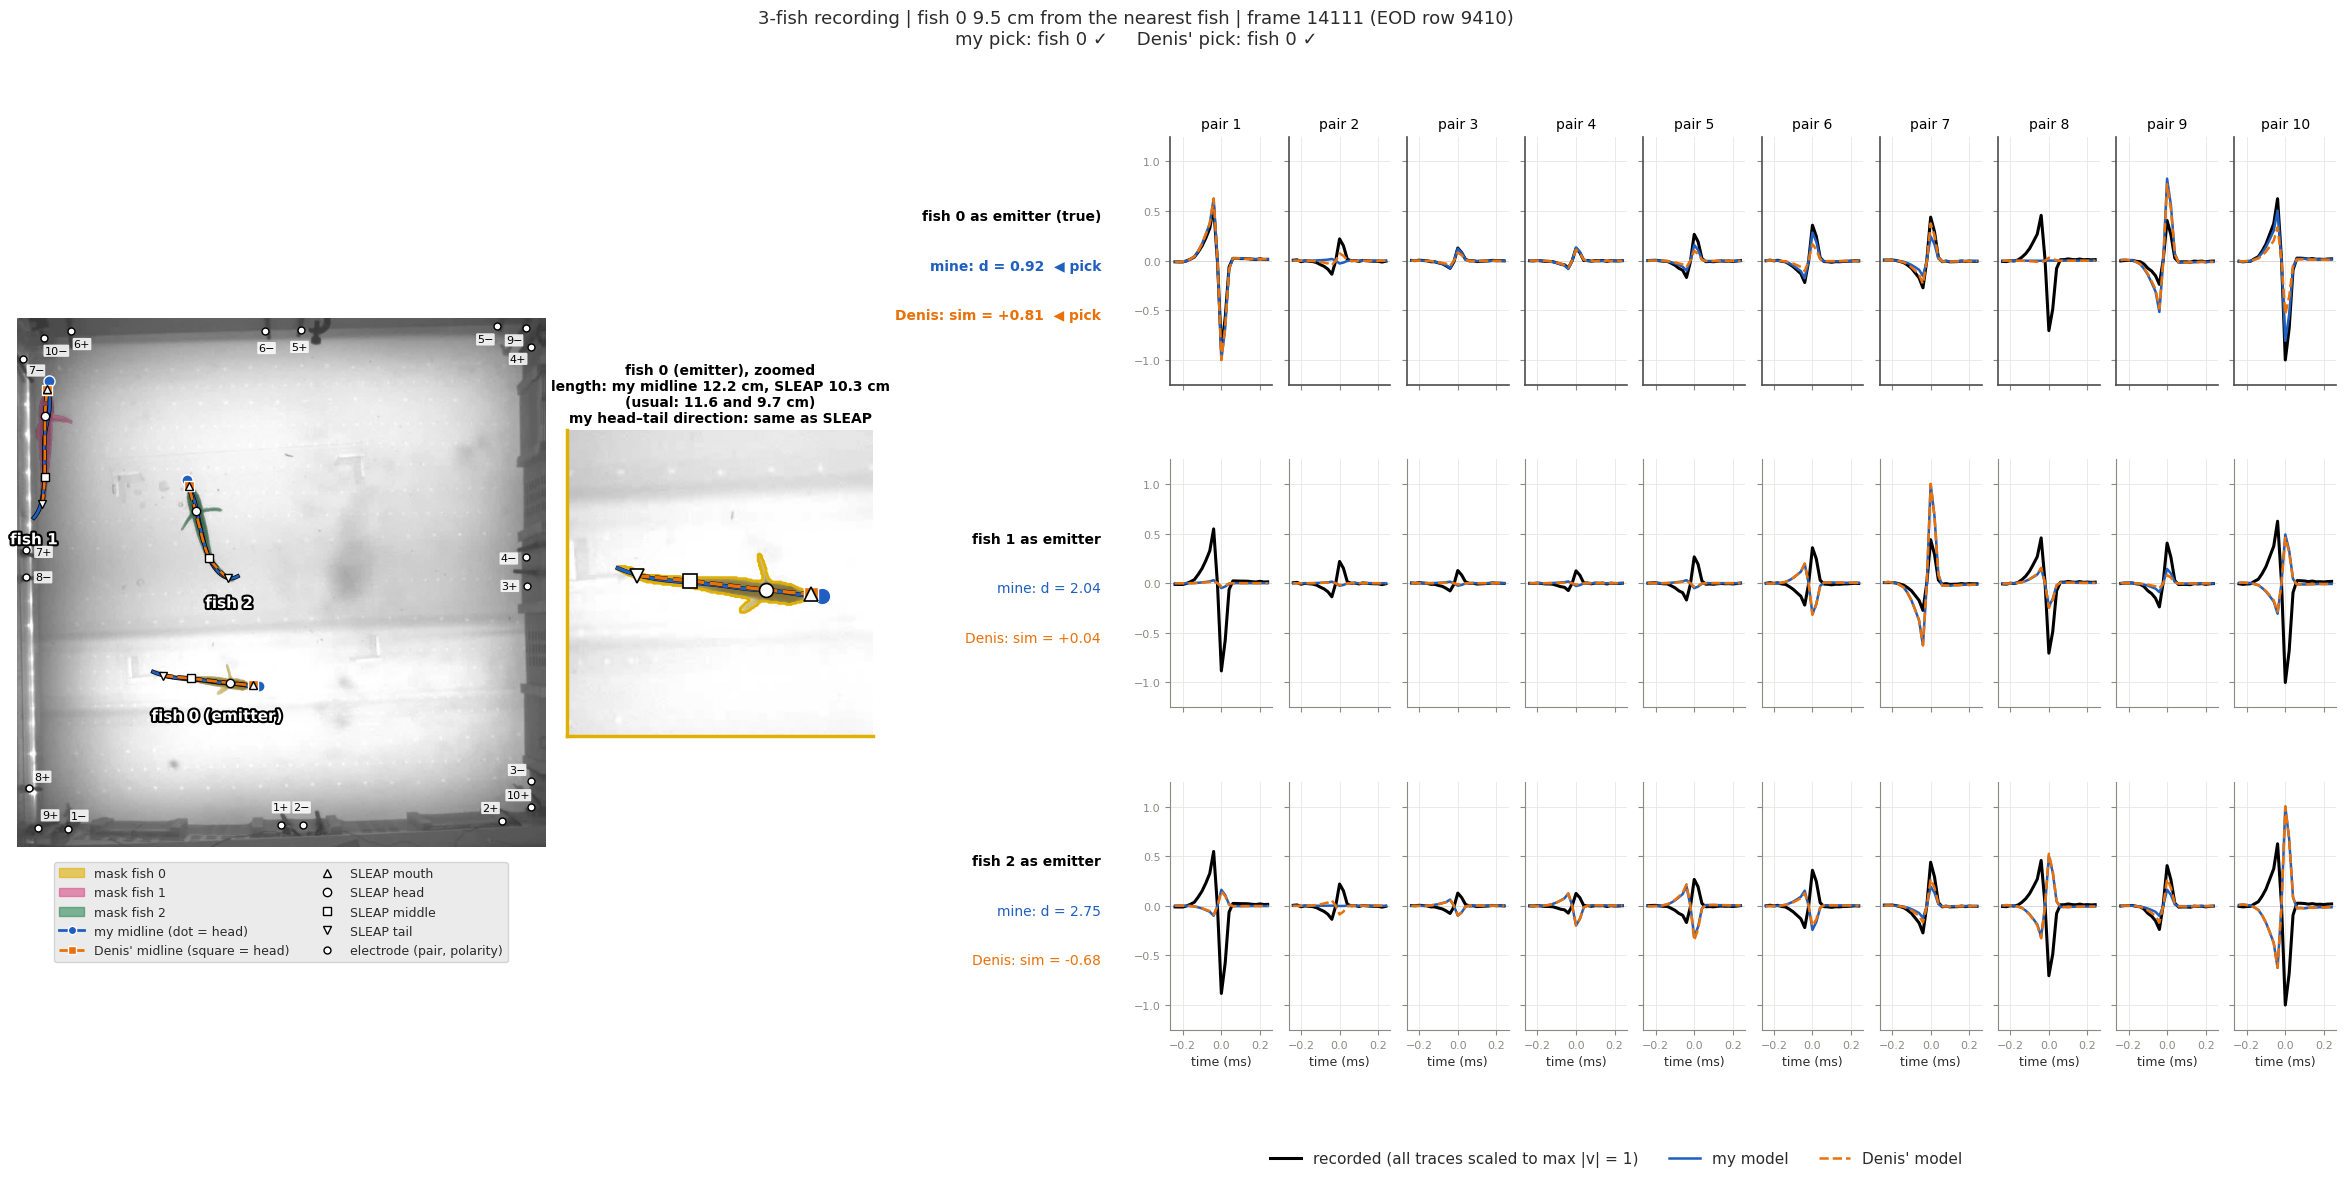

In [2]:
rows = c['df'].index[c['df'].Frame == FRAME]; i = int(rows[0]); a_ = c['assigned'].loc[i]; em = c['emitter']
print(f"frame {FRAME}: EOD row(s) {list(rows)} (using {i}) | in the better list: {a_['good frames']} | "
      f"fish {em} to nearest fish {a_.gap_cm:.1f} cm | my pick: fish {a_['fish | ' + ex.MINE]}, Denis: fish {a_['fish | ' + ex.DENIS]}")
ex.plot_example(c, i, f'3-fish recording | fish {em} {a_.gap_cm:.1f} cm from the nearest fish', f'{OUT}/frame{FRAME}_voltages.png')

## Field of each fish as the emitter (my model)

Colour: potential (red > 0, blue < 0; 0 = tank mean ≈ far field). Thin lines: equipotentials; **black: zero-potential line**; white:
field lines (E = −∇φ). Fish outlines, the emitting fish's midline (dot = head), electrodes with their potential. The solve is checked
against the cached voltages of `EOD_assignment_3_fish_conductivities.ipynb`.

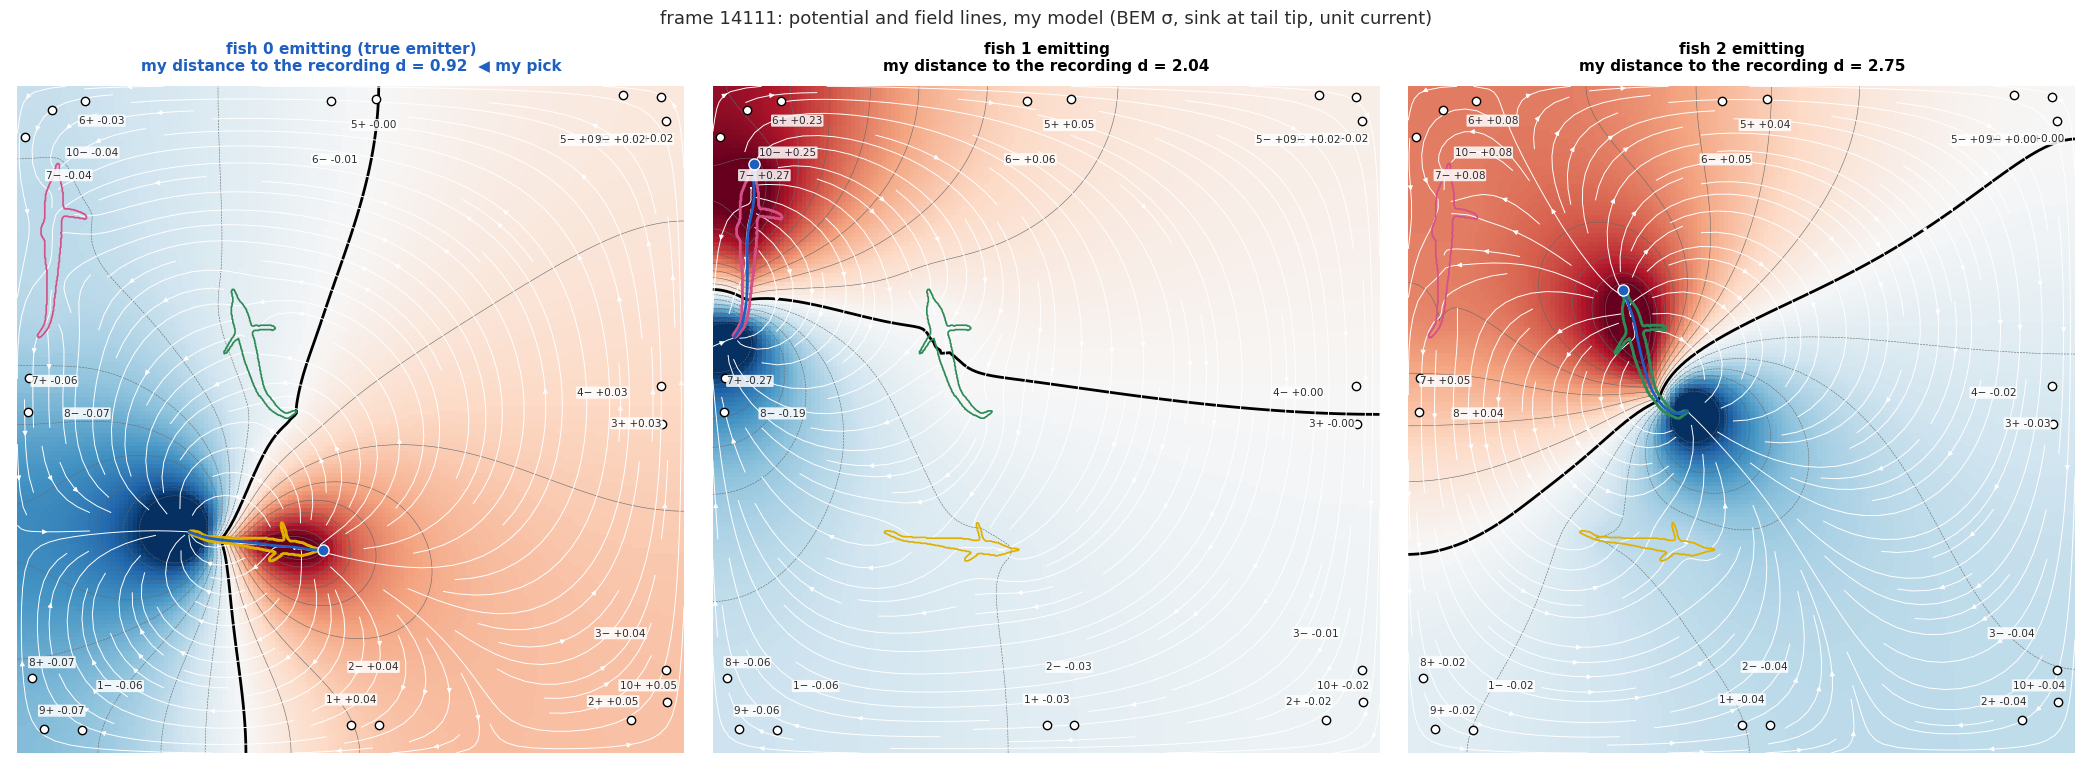

In [3]:
fm = ex.frame_masks(c, FRAME); mids = ex.fish_midlines(fm); P = c['P']
gw, gs, gi = gammas(0.0, **BEM)
phi = {}
for f in c['fish']:
    b = build_multipole_b(*multipole_sources(mids[f], I0=1.0, sink_frac=0.0), h, N)
    phi[f] = unflatten_to_grid(solve_potential(build_A_shell(occupancy_field(fm, N, skip=f), N, DELTA_H, gw, gs, gi), b), N).real

r, U = ex.my_patterns(c, i)                                         # cached: recorded pattern, model patterns (x -1, max |v| = 1)
for f in c['fish']:
    v = -pair_voltages(phi[f], c['pairs'], N); assert np.allclose(v / np.abs(v).max(), U[f], atol=1e-6)
d = np.linalg.norm(U - r, axis=1); pick = int(d.argmin())

g = np.linspace(0, P - 1, N)
fig, axs = plt.subplots(1, len(c['fish']), figsize=(7 * len(c['fish']), 7.6))
for a, f in zip(axs, c['fish']):
    p = phi[f]; v = np.percentile(np.abs(p), 99)
    a.imshow(p, extent=[0, P - 1, P - 1, 0], cmap='RdBu_r', vmin=-v, vmax=v)
    a.contour(g, g, p, levels=np.linspace(-v, v, 17), colors='0.4', linewidths=0.4)
    a.contour(g, g, p, levels=[0], colors='k', linewidths=2)
    Er, Ec = np.gradient(-p)                                        # E along rows, columns
    a.streamplot(g, g, Ec, Er, color='w', density=1.4, linewidth=0.7, arrowsize=0.7)
    for o in c['fish']:
        if fm[o].any(): a.contour(fm[o].astype(float), levels=[0.5], colors=[c['fish_color'][o]], linewidths=2 if o == f else 1.2)
    m = mids[f] * (P - 1); a.plot(m[:, 1], m[:, 0], color=ex.C_MINE, lw=2); a.plot(m[-1, 1], m[-1, 0], 'o', color=ex.C_MINE, mec='w', ms=8)
    for pid, pp, pm in c['pairs']:
        for pt, s in ((pp, '+'), (pm, '−')):
            y, x = pt * (P - 1); val = p[tuple(np.round(pt * (N - 1)).astype(int))]
            a.plot(x, y, 'o', color='w', mec='k', ms=6)
            off = np.array([P / 2 - x, P / 2 - y]); off = (35 if s == '+' else 80) * off / np.linalg.norm(off)   # + and − at two depths
            a.text(x + off[0], y + off[1], f'{pid}{s} {val:+.2f}', fontsize=7.5, ha='center', va='center',
                   bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.85))
    a.set(xlim=(-10, P + 10), ylim=(P + 10, -10)); a.set_axis_off()
    a.set_title(f"fish {f} emitting" + (' (true emitter)' if f == em else '') + f"\nmy distance to the recording d = {d[f]:.2f}" +
                ('  ◀ my pick' if f == pick else ''), fontsize=11, color=ex.C_MINE if f == pick else 'k')
plt.tight_layout(); fig.suptitle(f'frame {FRAME}: potential and field lines, my model (BEM σ, sink at tail tip, unit current)', fontsize=13, y=1.04); fig.savefig(f'{OUT}/frame{FRAME}_field.png', dpi=100, bbox_inches='tight'); plt.show()

## Orientation of the emitter relative to one electrode pair

Pair axis: from the − to the + electrode. Body axis: straight line tail tip → head of the emitter's mask midline. Tail axis: tail tip →
the midline point a fraction `TAIL_FRAC` of the body length from the tail tip (only the last bit of the body; three lengths shown).
Angles are as seen on the image (counter-clockwise > 0), from the pair axis to the fish axis; *acute* is the angle between the two
lines (0° = parallel, 90° = perpendicular), whatever the direction.

frame 14111, fish 0: midline 12.2 cm | pair 8: 8- -> 8+ 23.9 cm long, direction -89 deg on screen
  body (tail tip -> head)                          angle from pair axis   +81.6 deg | acute  81.6 deg | off perpendicular   8.4 deg
  tail, last 10% (1.2 cm; tail tip -> that point)  angle from pair axis   +70.2 deg | acute  70.2 deg | off perpendicular  19.8 deg
  tail, last 20% (2.4 cm; tail tip -> that point)  angle from pair axis   +73.8 deg | acute  73.8 deg | off perpendicular  16.2 deg
  tail, last 30% (3.6 cm; tail tip -> that point)  angle from pair axis   +76.8 deg | acute  76.8 deg | off perpendicular  13.2 deg


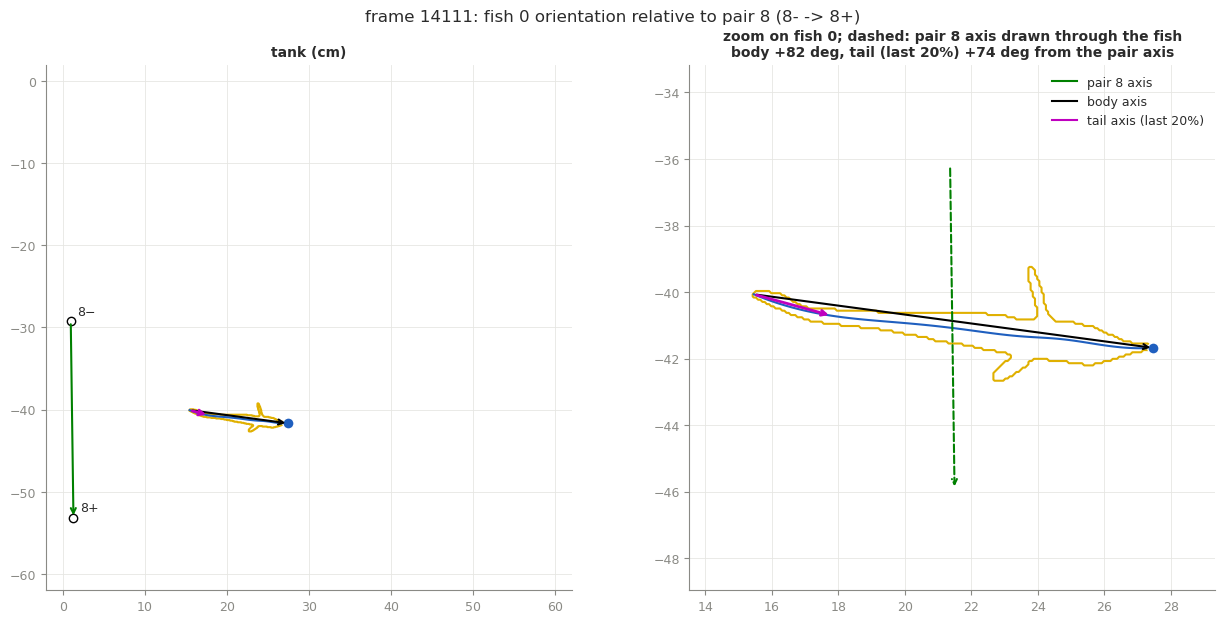

In [4]:
PAIR = 8
TAIL_FRACS = (0.1, 0.2, 0.3)                                        # last 10, 20, 30 % of the body
_, pp, pm = next(q for q in c['pairs'] if q[0] == PAIR)
xy = lambda pt: np.array([pt[1], -pt[0]]) * (P - 1) / ex.PX_PER_CM    # (row, col) / (P - 1) -> (x, y) in cm, y up as on screen
ang = lambda u, v: (np.degrees(np.arctan2(v[1], v[0]) - np.arctan2(u[1], u[0])) + 180) % 360 - 180
acute = lambda a: min(abs(a) % 180, 180 - abs(a) % 180)

m = np.array([xy(pt) for pt in mids[em]])                           # tail -> head
s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(m, axis=0), axis=1))]; L = s[-1]
along = lambda f: np.array([np.interp(f * L, s, m[:, 0]), np.interp(f * L, s, m[:, 1])])
u_pair = xy(pp) - xy(pm)
axes = {'body (tail tip -> head)': (m[0], m[-1])}
for tf in TAIL_FRACS: axes[f'tail, last {tf:.0%} ({tf * L:.1f} cm; tail tip -> that point)'] = (m[0], along(tf))
print(f"frame {FRAME}, fish {em}: midline {L:.1f} cm | pair {PAIR}: {PAIR}- -> {PAIR}+ {np.linalg.norm(u_pair):.1f} cm long, "
      f"direction {np.degrees(np.arctan2(u_pair[1], u_pair[0])):.0f} deg on screen")
for k, (a0, a1) in axes.items():
    a = ang(u_pair, a1 - a0)
    print(f"  {k:48s} angle from pair axis {a:+7.1f} deg | acute {acute(a):5.1f} deg | off perpendicular {90 - acute(a):5.1f} deg")

tf = 0.2                                                            # figure: tank (left) and zoom (right)
fig, axs = plt.subplots(1, 2, figsize=(13, 6.2))
for a in axs:
    a.contour(np.arange(P) / ex.PX_PER_CM, -np.arange(P) / ex.PX_PER_CM, fm[em].astype(float), levels=[0.5], colors=[c['fish_color'][em]])
    a.plot(m[:, 0], m[:, 1], color=ex.C_MINE, lw=1.5); a.plot(*m[-1], 'o', color=ex.C_MINE, mec='w', ms=8)
    a.annotate('', m[-1], m[0], arrowprops=dict(arrowstyle='->', color='k', lw=1.5))
    a.annotate('', along(tf), m[0], arrowprops=dict(arrowstyle='->', color='m', lw=2))
    a.annotate('', xy(pp), xy(pm), arrowprops=dict(arrowstyle='->', color='g', lw=1.5))
    for pt, sg in ((pp, '+'), (pm, '−')): a.plot(*xy(pt), 'o', color='w', mec='k'); a.text(*(xy(pt) + 0.8), f'{PAIR}{sg}', fontsize=9, clip_on=True)
    a.set_aspect('equal')
axs[0].set(xlim=(-2, P / ex.PX_PER_CM + 2), ylim=(-P / ex.PX_PER_CM - 2, 2), title=f'tank (cm)')
c0 = m.mean(0); axs[1].set(xlim=(c0[0] - 0.65 * L, c0[0] + 0.65 * L), ylim=(c0[1] - 0.65 * L, c0[1] + 0.65 * L))
for k, col in ((f'pair {PAIR} axis', 'g'), ('body axis', 'k'), (f'tail axis (last {tf:.0%})', 'm')):   # pair axis also through the fish
    if col == 'g': axs[1].annotate('', c0 + 0.4 * L * u_pair / np.linalg.norm(u_pair), c0 - 0.4 * L * u_pair / np.linalg.norm(u_pair),
                                   arrowprops=dict(arrowstyle='->', color='g', lw=1.5, ls='--'))
    axs[1].plot([], [], color=col, label=k)
axs[1].legend(loc='upper right', fontsize=9)
axs[1].set_title(f"zoom on fish {em}; dashed: pair {PAIR} axis drawn through the fish\n"
                 f"body {ang(u_pair, m[-1] - m[0]):+.0f} deg, tail (last {tf:.0%}) {ang(u_pair, along(tf) - m[0]):+.0f} deg from the pair axis",
                 fontsize=10)
fig.suptitle(f'frame {FRAME}: fish {em} orientation relative to pair {PAIR} ({PAIR}- -> {PAIR}+)', fontsize=12)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_orientation_pair{PAIR}.png', dpi=100, bbox_inches='tight'); plt.show()

## Rotating the emitter's whole body

The emitter's midline is rotated clockwise (as seen on the image) about its centroid by `ROT_DEG`; the other two fish stay as bodies where
they are (the emitter's own mask is not in the conductivity, so only its sources move). Pair voltages as compared with the recording:
× −1 and scaled to max |v| = 1 over the 10 pairs (the scale is that of each rotated pattern).

frame 14111, fish 0, pair 8: recorded -0.70 (of the largest pair)
 rotation  body vs pair axis  pair 8 scaled  change  raw x -1  largest pair  d (fish 0)
      0 °            +81.6 °         +0.001  +0.000   +0.0001             1        0.92
      5 °            +76.6 °         -0.113  -0.114   -0.0109             1        0.76
     10 °            +71.6 °         -0.233  -0.235   -0.0215             1        0.61
     15 °            +66.6 °         -0.335  -0.336   -0.0316            10        0.48
     20 °            +61.6 °         -0.420  -0.421   -0.0409            10        0.41
     25 °            +56.6 °         -0.495  -0.496   -0.0494            10        0.43
     30 °            +51.6 °         -0.562  -0.564   -0.0571            10        0.51


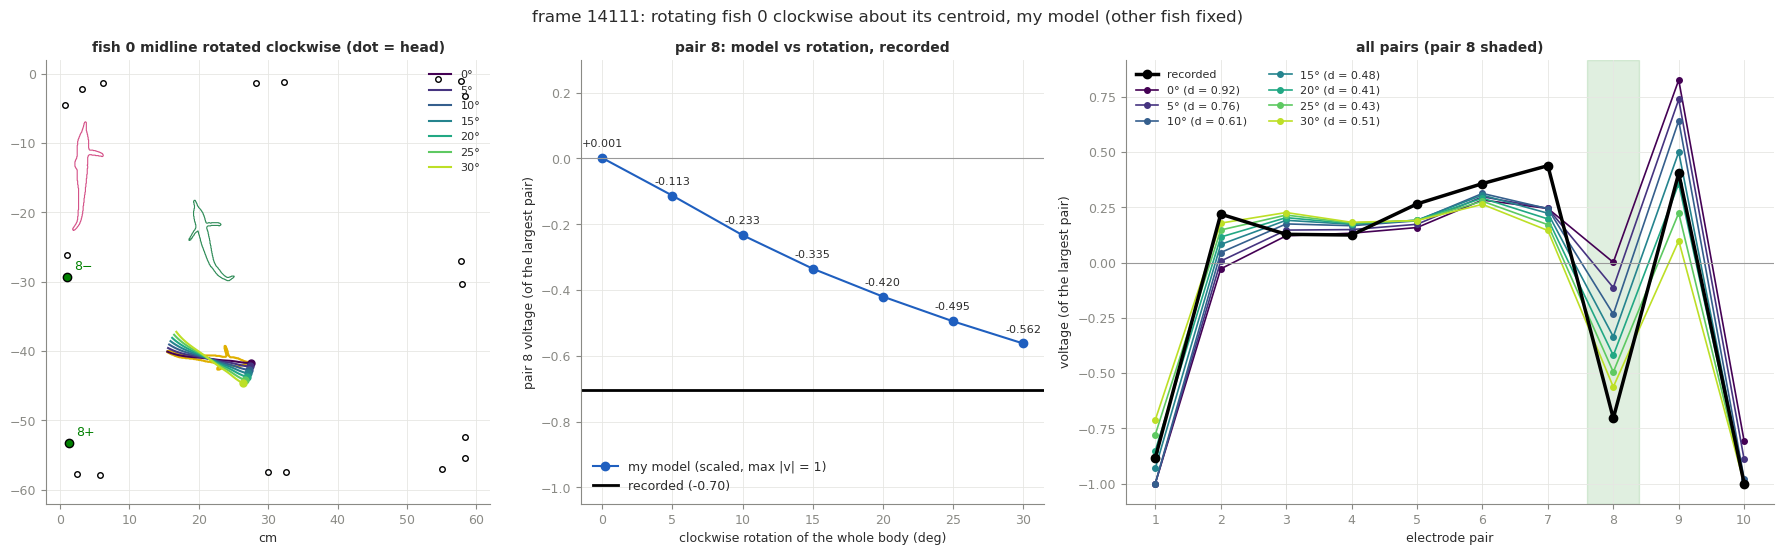

In [5]:
ROT_DEG = (0, 5, 10, 15, 20, 25, 30)                                        # clockwise on screen
k8 = c['pair_ids'].index(PAIR)
A_em = build_A_shell(occupancy_field(fm, N, skip=em), N, DELTA_H, gw, gs, gi)
def rotate_cw(mid, deg):                                            # (row, col) midline, clockwise on screen about its centroid
    t = np.radians(deg); c0 = mid.mean(0); dr, dc = (mid - c0).T
    return c0 + np.c_[dc * np.sin(t) + dr * np.cos(t), dc * np.cos(t) - dr * np.sin(t)]
rot = {}
for deg in ROT_DEG:
    mr = rotate_cw(mids[em], deg)
    p = unflatten_to_grid(solve_potential(A_em, build_multipole_b(*multipole_sources(mr, I0=1.0, sink_frac=0.0), h, N)), N).real
    v = -pair_voltages(p, c['pairs'], N)                            # x -1, unit current
    rot[deg] = dict(mid=mr, v=v, u=v / np.abs(v).max())
assert np.allclose(rot[0]['u'], U[em], atol=1e-6)                   # 0 deg = the original model
print(f"frame {FRAME}, fish {em}, pair {PAIR}: recorded {r[k8]:+.2f} (of the largest pair)")
print(f"{'rotation':>9s} {'body vs pair axis':>18s} {'pair ' + str(PAIR) + ' scaled':>14s} {'change':>7s} {'raw x -1':>9s} {'largest pair':>13s} {'d (fish ' + str(em) + ')':>11s}")
for deg, q in rot.items():
    q['d'] = np.linalg.norm(q['u'] - r)
    print(f"{deg:>7d} ° {ang(u_pair, xy(q['mid'][-1]) - xy(q['mid'][0])):>+16.1f} ° {q['u'][k8]:>+14.3f} {q['u'][k8] - rot[0]['u'][k8]:>+7.3f} "
          f"{q['v'][k8]:>+9.4f} {c['pair_ids'][int(np.abs(q['v']).argmax())]:>13d} {q['d']:>11.2f}")

cols = plt.cm.viridis(np.linspace(0, 0.9, len(ROT_DEG)))
fig, axs = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw=dict(width_ratios=[1, 1, 1.4]))
a = axs[0]                                                          # tank: rotated midlines and pair 8
a.contour(np.arange(P) / ex.PX_PER_CM, -np.arange(P) / ex.PX_PER_CM, fm[em].astype(float), levels=[0.5], colors=[c['fish_color'][em]])
for o in c['fish']:
    if o != em and fm[o].any(): a.contour(np.arange(P) / ex.PX_PER_CM, -np.arange(P) / ex.PX_PER_CM, fm[o].astype(float), levels=[0.5], colors=[c['fish_color'][o]], linewidths=0.8)
for (deg, q), col in zip(rot.items(), cols):
    mm = np.array([xy(pt) for pt in q['mid']]); a.plot(mm[:, 0], mm[:, 1], color=col, lw=1.5, label=f'{deg}°'); a.plot(*mm[-1], 'o', color=col, ms=5)
for pid, pp_, pm_ in c['pairs']:
    for pt, sg in ((pp_, '+'), (pm_, '−')):
        a.plot(*xy(pt), 'o', color='g' if pid == PAIR else 'w', mec='k', ms=6 if pid == PAIR else 4)
        if pid == PAIR: a.text(*(xy(pt) + 1), f'{PAIR}{sg}', fontsize=9, color='g')
a.set(xlim=(-2, P / ex.PX_PER_CM + 2), ylim=(-P / ex.PX_PER_CM - 2, 2), aspect='equal', xlabel='cm', title=f'fish {em} midline rotated clockwise (dot = head)')
a.legend(fontsize=8, loc='upper right')
a = axs[1]                                                          # pair 8 vs rotation
a.plot(ROT_DEG, [q['u'][k8] for q in rot.values()], 'o-', color=ex.C_MINE, label=f'my model (scaled, max |v| = 1)')
a.axhline(r[k8], color='k', lw=2, label=f'recorded ({r[k8]:+.2f})'); a.axhline(0, color='0.6', lw=0.8)
for deg, q in rot.items(): a.annotate(f"{q['u'][k8]:+.3f}", (deg, q['u'][k8]), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
a.set(xticks=ROT_DEG, xlabel='clockwise rotation of the whole body (deg)', ylabel=f'pair {PAIR} voltage (of the largest pair)', ylim=(-1.05, 0.3),
      title=f'pair {PAIR}: model vs rotation, recorded')
a.legend(fontsize=9, loc='lower left')
a = axs[2]                                                          # whole pattern
x = np.arange(len(c['pair_ids']))
a.plot(x, r, 'k-o', lw=2.5, label='recorded', zorder=5)
for (deg, q), col in zip(rot.items(), cols): a.plot(x, q['u'], 'o-', color=col, lw=1.2, ms=4, label=f"{deg}° (d = {q['d']:.2f})")
a.axvspan(k8 - 0.4, k8 + 0.4, color='g', alpha=0.12); a.axhline(0, color='0.6', lw=0.8)
a.set(xticks=x, xticklabels=c['pair_ids'], xlabel='electrode pair', ylabel='voltage (of the largest pair)', title='all pairs (pair 8 shaded)')
a.legend(fontsize=8, ncol=2)
fig.suptitle(f'frame {FRAME}: rotating fish {em} clockwise about its centroid, my model (other fish fixed)', fontsize=12)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_rotation_pair{PAIR}.png', dpi=100, bbox_inches='tight'); plt.show()

## Several sinks at the tail

Original midline (no rotation), 101 points tail → head. The first `K` points from the tail tip are sinks of −1/K each, the other 101 − K
points sources of +1/(101 − K) each, so the currents sum to 0 (K = 1 is the original model, `multipole_sources` with sink_frac = 0).
Local to this notebook; `multipole_sources` is not changed. Pair voltages × −1 and scaled to max |v| = 1 over the 10 pairs.

frame 14111, fish 0: midline 12.2 cm, 101 points 0.122 cm apart; grid cell 0.402 cm
 K sinks  tail cm  sum -  sum +     p1     p2     p3     p4     p5     p6     p7     p8     p9    p10     d
                        recorded  -0.88  +0.22  +0.13  +0.12  +0.27  +0.36  +0.44  -0.70  +0.40  -1.00
       1     0.00  -1.00  +1.00  -1.00  -0.03  +0.12  +0.13  +0.16  +0.28  +0.25  +0.00  +0.83  -0.81  0.92
       2     0.12  -1.00  +1.00  -1.00  -0.03  +0.12  +0.13  +0.16  +0.28  +0.24  +0.01  +0.83  -0.81  0.92
       3     0.24  -1.00  +1.00  -1.00  -0.03  +0.12  +0.13  +0.16  +0.28  +0.24  +0.01  +0.83  -0.80  0.93
       5     0.49  -1.00  +1.00  -1.00  -0.03  +0.12  +0.13  +0.16  +0.28  +0.24  +0.02  +0.83  -0.80  0.94
      10     1.09  -1.00  +1.00  -1.00  -0.04  +0.12  +0.13  +0.16  +0.28  +0.24  +0.04  +0.84  -0.79  0.96
      15     1.70  -1.00  +1.00  -1.00  -0.04  +0.12  +0.13  +0.16  +0.27  +0.23  +0.05  +0.85  -0.79  0.98


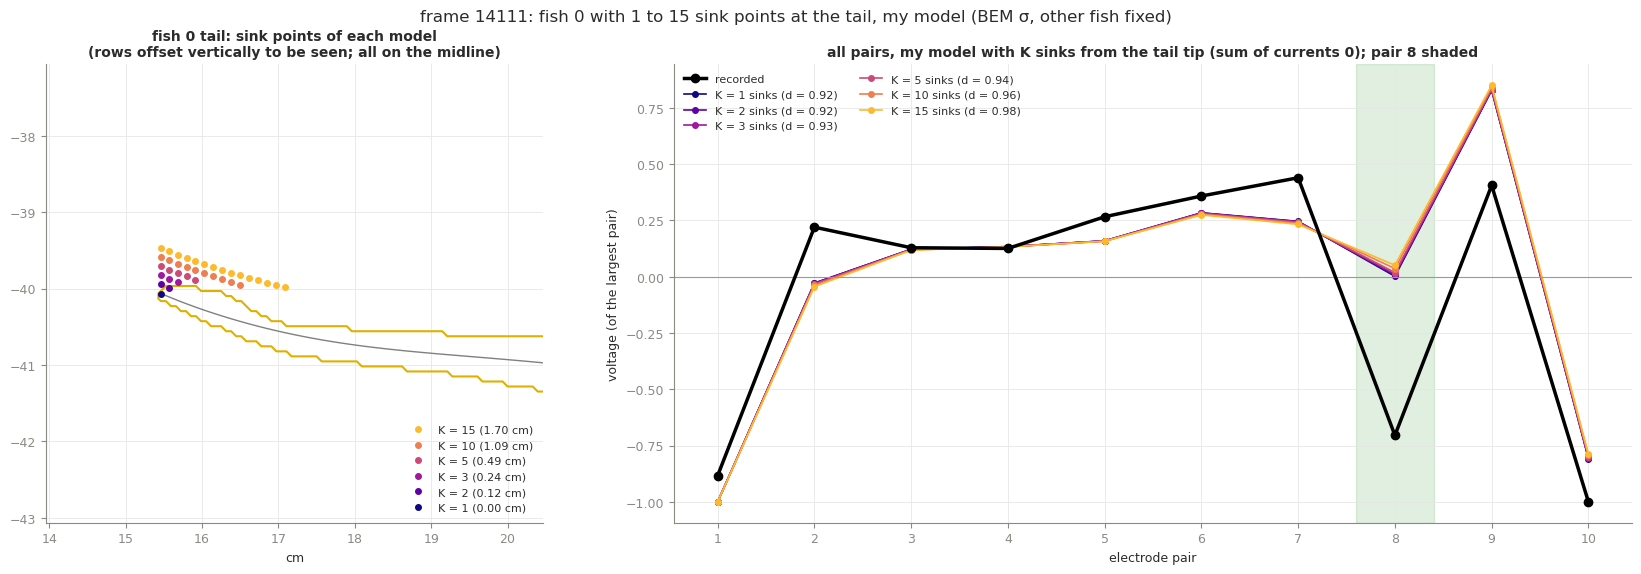

In [6]:
SINKS = (1, 2, 3, 5, 10, 15)                                        # number of consecutive sink points from the tail tip
def multipole_sinks(mid, K, I0=1.0):
    n1 = len(mid); cur = np.r_[np.full(K, -1.0 / K), np.full(n1 - K, 1.0 / (n1 - K))] * I0
    assert abs(cur.sum()) < 1e-12 and np.isclose(cur[cur < 0].sum(), -I0) and np.isclose(cur[cur > 0].sum(), I0)
    return np.asarray(mid, float), cur
ms = mids[em]; seg = np.r_[0, np.cumsum(np.linalg.norm(np.diff(ms * (P - 1), axis=0), axis=1))] / ex.PX_PER_CM   # arc length (cm) from the tail tip
sk = {}
for K in SINKS:
    pos, cur = multipole_sinks(ms, K)
    p = unflatten_to_grid(solve_potential(A_em, build_multipole_b(pos, cur, h, N)), N).real
    v = -pair_voltages(p, c['pairs'], N)
    sk[K] = dict(v=v, u=v / np.abs(v).max(), cm=seg[K - 1], sum_minus=cur[cur < 0].sum(), sum_plus=cur[cur > 0].sum())
    sk[K]['d'] = np.linalg.norm(sk[K]['u'] - r)
assert np.allclose(sk[1]['u'], U[em], atol=1e-6)                    # K = 1 = the original model
print(f"frame {FRAME}, fish {em}: midline {seg[-1]:.1f} cm, {len(ms)} points {seg[1]:.3f} cm apart; grid cell {CELL_CM:.3f} cm")
print(f"{'K sinks':>8s} {'tail cm':>8s} {'sum -':>6s} {'sum +':>6s} " + ' '.join(f'{"p" + str(q):>6s}' for q in c['pair_ids']) + f" {'d':>5s}")
print(f"{'recorded':>32s} " + ' '.join(f'{x:+6.2f}' for x in r))
for K, q in sk.items():
    print(f"{K:>8d} {q['cm']:>8.2f} {q['sum_minus']:>+6.2f} {q['sum_plus']:>+6.2f} " + ' '.join(f'{x:+6.2f}' for x in q['u']) + f" {q['d']:5.2f}")

cols = plt.cm.plasma(np.linspace(0, 0.85, len(SINKS)))
fig, axs = plt.subplots(1, 2, figsize=(17, 5.8), gridspec_kw=dict(width_ratios=[1, 1.6]))
a = axs[0]                                                          # zoom on the tail: sink points of each model
mc = np.array([xy(pt) for pt in ms])
a.contour(np.arange(P) / ex.PX_PER_CM, -np.arange(P) / ex.PX_PER_CM, fm[em].astype(float), levels=[0.5], colors=[c['fish_color'][em]])
a.plot(mc[:, 0], mc[:, 1], color='0.5', lw=1); a.plot(*mc[-1], 'o', color=ex.C_MINE, mec='w', ms=8)
for j, (K, col) in enumerate(zip(SINKS[::-1], cols[::-1])):
    a.plot(mc[:K, 0], mc[:K, 1] + 0.12 * (len(SINKS) - 1 - j), 'o', color=col, ms=4, label=f'K = {K} ({sk[K]["cm"]:.2f} cm)')
a.set(xlim=(mc[0, 0] - 1.5, mc[0, 0] + 5), ylim=(mc[0, 1] - 3, mc[0, 1] + 3), aspect='equal', xlabel='cm',
      title=f'fish {em} tail: sink points of each model\n(rows offset vertically to be seen; all on the midline)')
a.legend(fontsize=8, loc='lower right')
a = axs[1]
x = np.arange(len(c['pair_ids']))
a.plot(x, r, 'k-o', lw=2.5, label='recorded', zorder=5)
for (K, q), col in zip(sk.items(), cols): a.plot(x, q['u'], 'o-', color=col, lw=1.2, ms=4, label=f"K = {K} sinks (d = {q['d']:.2f})")
a.axvspan(k8 - 0.4, k8 + 0.4, color='g', alpha=0.12); a.axhline(0, color='0.6', lw=0.8)
a.set(xticks=x, xticklabels=c['pair_ids'], xlabel='electrode pair', ylabel='voltage (of the largest pair)',
      title=f'all pairs, my model with K sinks from the tail tip (sum of currents 0); pair {PAIR} shaded')
a.legend(fontsize=8, ncol=2)
fig.suptitle(f'frame {FRAME}: fish {em} with 1 to {max(SINKS)} sink points at the tail, my model (BEM σ, other fish fixed)', fontsize=12)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_sinks.png', dpi=100, bbox_inches='tight'); plt.show()

## Emitter as a body with the sources inside (thesis model, Rother: *Gnathonemus petersii*, BEM, ch. 2–3)

So far the emitter is transparent (water) and its currents sit along the midline. Here the emitter is a body like the other fish:
interior + thin resistive skin, with conductivities that change along the length, and the currents are inside it.
Thesis values (water σ_w = 1e-4 S/cm, so interior 0.01 S/cm = 100 × water, as in our BEM):
- **skin** (conductance per area, by zone along the body, fraction from the snout): mormyromast epithelium 0–30 % (dorsal 2e-4,
  ventral 6e-4 S/cm²; mean 4e-4 used, the 2D model sees the sides), gill 30–36 % (5e-3), non-mormyromast lateral/caudal skin 36–100 %
  (3e-3). Our BEM skin so far: 1e-3 S/cm² everywhere (as resistive as 0.1 cm of water).
- **interior**: 0.01 S/cm in the thesis' final model; their profile (Fig. 3-4) is ≈ 0.004 S/cm from the head to 75 %, rising to
  0.015 S/cm at 90 % (mouth artefact left out).
- **sources**: the electric organ in the caudal peduncle, one sink and one source (Fig. 3-7: at ≈ 5 % and ≈ 18 % of the body
  from its posterior end). Kept with our polarity (sink posterior), as our sign rule (× −1) is set for it; the thesis draws the
  opposite polarity, which only flips the sign of every pair.

Each current goes on the nearest grid node inside the emitter (its tail is ~1 grid cell wide at N = 150, so bilinear spreading would
put part of it in the water). The other two fish stay uniform BEM bodies. The skin is the same thin sheet as in `build_A_shell`, with
per-node values (`build_A_var` here, checked against `build_A_shell` for uniform values); nothing in the shared code changes.

frame 14111: pair voltages (x -1, max |v| = 1) with fish 0 (true emitter) emitting; d to the recording for each candidate fish
                                                          p1     p2     p3     p4     p5     p6     p7     p8     p9    p10   d(f0) d(f1) d(f2)  pick
recorded                                               -0.88  +0.22  +0.13  +0.12  +0.27  +0.36  +0.44  -0.70  +0.40  -1.00
original: emitter transparent, sink at tail tip + sour -1.00  -0.03  +0.12  +0.13  +0.16  +0.28  +0.25  +0.00  +0.83  -0.81    0.92  2.04  2.75  fish 0
body (σ 100, BEM skin), original sources inside        -1.00  -0.01  +0.13  +0.14  +0.16  +0.29  +0.25  -0.05  +0.79  -0.83    0.85  1.98  2.76  fish 0
body (σ 100, BEM skin), EO sink/source in the tail     -1.00  +0.01  +0.13  +0.14  +0.16  +0.30  +0.26  -0.09  +0.77  -0.85    0.79  1.94  2.79  fish 0
body (σ 100, thesis skin zones), EO in the tail        -1.00  +0.01  +0.13  +0.14  +0.16  +0.30  +0.26  -0.09  +0.77  -0.84    0.80  1.94  2.79

first row (original), grid N = 300                     -1.00  -0.03  +0.12  +0.13  +0.16  +0.28  +0.23  +0.01  +0.83  -0.80   d(f0) = 0.93
last row, grid N = 300                                 -1.00  -0.00  +0.12  +0.13  +0.15  +0.29  +0.25  -0.03  +0.80  -0.81   d(f0) = 0.87


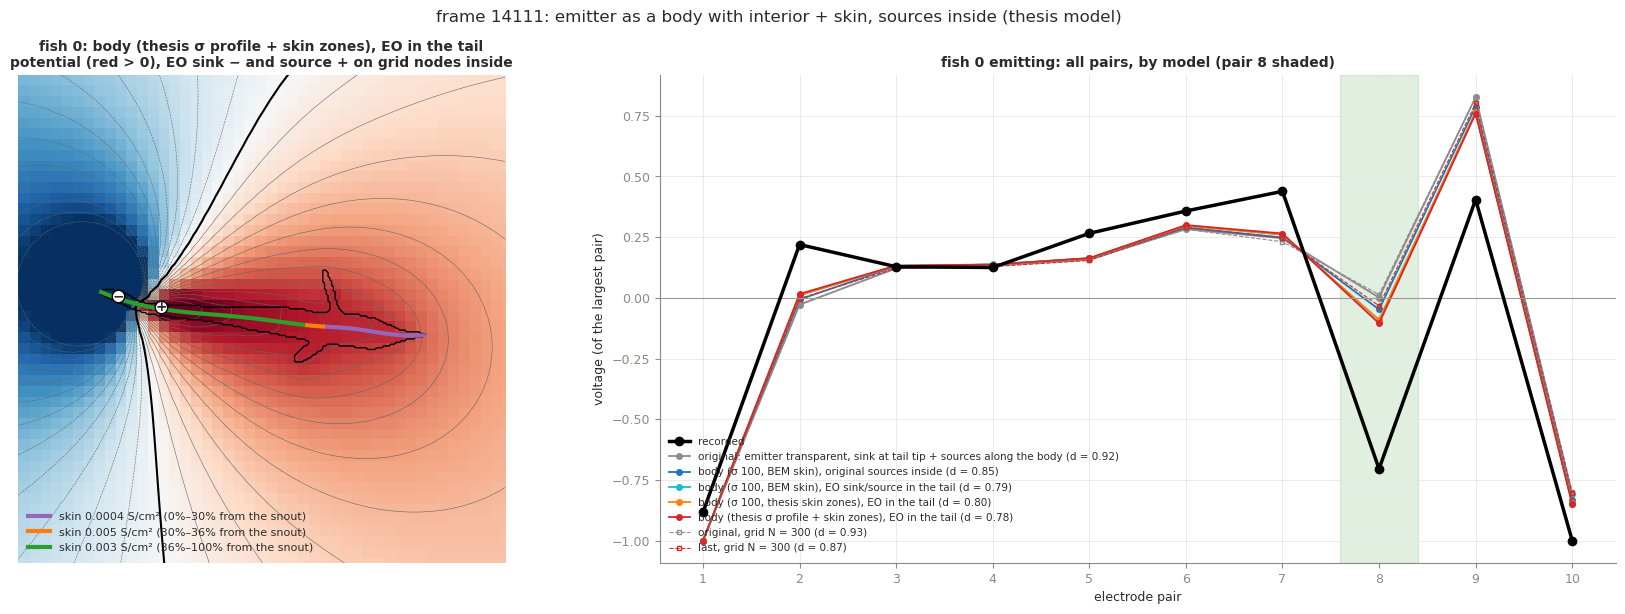

In [7]:
import scipy.sparse as sp
from compute_electric_field import theta_outer
SIG_W = 1e-4                                                        # water, S/cm
SKIN_T = 0.005                                                      # skin thickness, cm (as in BEM)
SKIN_ZONES = [(0.00, 0.30, 4e-4), (0.30, 0.36, 5e-3), (0.36, 1.01, 3e-3)]   # fraction from the snout, S/cm^2
INT_PROFILE = ([0.0, 0.75, 0.90, 1.0], [0.004, 0.004, 0.015, 0.014])         # fraction from the snout, S/cm
EO = (0.05, 0.18)                                                   # sink, source: fraction of body length from the tail tip
G_SKIN_BEM = SIG_W / 0.1                                            # skin used so far, S/cm^2
g_skin_of = lambda G, g_int: 1 / (SIG_W / G / SKIN_T + 1 / g_int)   # skin σ (x water) over SKIN_T giving conductance G

def build_A_var(occ, N_, delta_h, gnode, gskin):
    '''build_A_shell with per-node values: gnode water / interior σ, gskin the skin σ of interior nodes (x water). Uncut edges:
       harmonic mean of the two nodes; cut edges: medium | skin sheet | medium in series, skin of the edge's interior node.'''
    tx, ty = theta_outer(occ); ins = occ > 0.5; idx = np.arange(N_ * N_).reshape(N_, N_); R, C, V = [], [], []
    for th, a, b in ((tx, np.s_[:-1, :], np.s_[1:, :]), (ty, np.s_[:, :-1], np.s_[:, 1:])):
        gA, gB = gnode[a], gnode[b]; gi = np.where(ins[a], gA, gB); gs = np.where(ins[a], gskin[a], gskin[b])
        t = np.nan_to_num(th)
        w = np.where(np.isnan(th), 2 / (1 / gA + 1 / gB), 1 / (t / gA + (1 - t) / gB + delta_h * (1 / gs - 1 / gi)))
        R += [idx[a].ravel(), idx[b].ravel()]; C += [idx[b].ravel(), idx[a].ravel()]; V += [w.ravel()] * 2
    A = sp.coo_matrix((np.concatenate(V), (np.concatenate(R), np.concatenate(C))), shape=(N_ * N_,) * 2).tocsr()
    return (A - sp.diags(np.asarray(A.sum(axis=1)).ravel())).astype(complex)

def body_maps(f, N_, skin, interior, skin_scale=1.0, int_scale=1.0):
    '''Conductivity maps with fish f as a body: skin 'bem' or 'zones', interior 'uniform' (100 x water) or 'profile';
       skin_scale, int_scale multiply all of the emitter's skin conductances / interior conductivities (ratios along the body kept).'''
    occ = occupancy_field(fm, N_); ins = occ > 0.5
    gnode = np.where(ins, BEM['sigma_interior'], 1.0); gskin = np.where(ins, BEM['sigma_skin'], 1.0)
    own = occupancy_field([fm[f]], N_) > 0.5; ii, jj = np.nonzero(own)
    m = mids[f] * (N_ - 1); s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(m, axis=0), axis=1))]; s /= s[-1]
    snout = 1 - s[np.argmin(((np.c_[ii, jj][:, None, :] - m[None]) ** 2).sum(-1), axis=1)]   # node's fraction from the snout
    g_int = np.full(len(ii), BEM['sigma_interior']) if interior == 'uniform' else np.interp(snout, *INT_PROFILE) / SIG_W
    G = np.full(len(ii), G_SKIN_BEM) if skin == 'bem' else np.select([(snout >= a) & (snout < b) for a, b, _ in SKIN_ZONES], [g for *_, g in SKIN_ZONES])
    g_int = g_int * int_scale; G = G * skin_scale
    gnode[ii, jj] = g_int; gskin[ii, jj] = g_skin_of(G, g_int)
    return occ, gnode, gskin, own, m, s

def inside_b(points, cur, own, N_):
    '''Each current on the nearest grid node inside the emitter.'''
    ii, jj = np.nonzero(own); b = np.zeros((N_, N_)); nodes = []
    for pt, I in zip(points, cur):
        k = np.argmin((ii - pt[0]) ** 2 + (jj - pt[1]) ** 2); b[ii[k], jj[k]] += I; nodes.append((ii[k], jj[k]))
    assert abs(b.sum()) < 1e-12
    return b, nodes

def eo_points(m, s): return np.array([[np.interp(f, s, m[:, 0]), np.interp(f, s, m[:, 1])] for f in EO])

occ0 = occupancy_field(fm, N); g0 = np.where(occ0 > 0.5, BEM['sigma_interior'], 1.0); s0 = np.where(occ0 > 0.5, BEM['sigma_skin'], 1.0)
assert abs(build_A_var(occ0, N, DELTA_H, g0, s0) - build_A_shell(occ0, N, DELTA_H, gw, gs, gi)).max() < 1e-9   # = build_A_shell when uniform

VARIANTS = [('original: emitter transparent, sink at tail tip + sources along the body', None),
            ('body (σ 100, BEM skin), original sources inside', ('bem', 'uniform', 'orig')),
            ('body (σ 100, BEM skin), EO sink/source in the tail', ('bem', 'uniform', 'eo')),
            ('body (σ 100, thesis skin zones), EO in the tail', ('zones', 'uniform', 'eo')),
            ('body (thesis σ profile + skin zones), EO in the tail', ('zones', 'profile', 'eo'))]
def solve_variant(f, spec, N_, skin_scale=1.0, int_scale=1.0):
    skin, interior, src = spec
    occ, gnode, gskin, own, m, s = body_maps(f, N_, skin, interior, skin_scale, int_scale)
    pts, cur = (multipole_sources(m, I0=1.0, sink_frac=0.0) if src == 'orig' else (eo_points(m, s), np.array([-1.0, 1.0])))
    b, nodes = inside_b(pts, cur, own, N_)
    p = unflatten_to_grid(solve_potential(build_A_var(occ, N_, SKIN_T / ((P - 1) / (N_ - 1) / ex.PX_PER_CM), gnode, gskin), b), N_).real
    return p, nodes, gnode
res = {}
for name, spec in VARIANTS:
    for f in c['fish']:
        if spec is None: res[name, f] = dict(u=U[f]); continue
        p, nodes, gnode = solve_variant(f, spec, N)
        v = -pair_voltages(p, c['pairs'], N); res[name, f] = dict(u=v / np.abs(v).max(), p=p, nodes=nodes, gnode=gnode)
for key in res: res[key]['d'] = np.linalg.norm(res[key]['u'] - r)

print(f"frame {FRAME}: pair voltages (x -1, max |v| = 1) with fish {em} (true emitter) emitting; d to the recording for each candidate fish")
print(f"{'':54s}" + ' '.join(f'{"p" + str(q):>6s}' for q in c['pair_ids']) + '   ' + ' '.join(f'd(f{f})' for f in c['fish']) + '  pick')
print(f"{'recorded':54s}" + ' '.join(f'{x:+6.2f}' for x in r))
for name, _ in VARIANTS:
    ds = [res[name, f]['d'] for f in c['fish']]
    print(f"{name[:54]:54s}" + ' '.join(f'{x:+6.2f}' for x in res[name, em]['u']) + '   ' + ' '.join(f'{x:5.2f}' for x in ds) + f"  fish {c['fish'][int(np.argmin(ds))]}")

N2 = 300                                                            # resolution check of the last variant (fish em only)
p2, _, _ = solve_variant(em, VARIANTS[-1][1], N2); v2 = -pair_voltages(p2, c['pairs'], N2); u2 = v2 / np.abs(v2).max()
oc2 = occupancy_field(fm, N2, skip=em); ins2 = oc2 > 0.5                # the original model at N2 too, for the same-grid comparison
A2 = build_A_var(oc2, N2, SKIN_T / ((P - 1) / (N2 - 1) / ex.PX_PER_CM), np.where(ins2, BEM['sigma_interior'], 1.0), np.where(ins2, BEM['sigma_skin'], 1.0))
po2 = unflatten_to_grid(solve_potential(A2, build_multipole_b(*multipole_sources(mids[em], I0=1.0, sink_frac=0.0), 1 / (N2 - 1), N2)), N2).real
vo2 = -pair_voltages(po2, c['pairs'], N2); uo2 = vo2 / np.abs(vo2).max()
print(f"{'first row (original), grid N = ' + str(N2):54s}" + ' '.join(f'{x:+6.2f}' for x in uo2) + f"   d(f{em}) = {np.linalg.norm(uo2 - r):.2f}")
print(f"{'last row, grid N = ' + str(N2):54s}" + ' '.join(f'{x:+6.2f}' for x in u2) + f"   d(f{em}) = {np.linalg.norm(u2 - r):.2f}")

last = res[VARIANTS[-1][0], em]
fig, axs = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw=dict(width_ratios=[1, 1.5]))
a = axs[0]; pz = last['p']; vv = np.percentile(np.abs(pz), 99.5)
a.imshow(pz, extent=[0, P - 1, P - 1, 0], cmap='RdBu_r', vmin=-vv, vmax=vv)
a.contour(g, g, pz, levels=np.linspace(-vv, vv, 25), colors='0.4', linewidths=0.4); a.contour(g, g, pz, levels=[0], colors='k', linewidths=1.5)
a.contour(fm[em].astype(float), levels=[0.5], colors='k', linewidths=1)
mm = mids[em] * (P - 1); sm = np.r_[0, np.cumsum(np.linalg.norm(np.diff(mm, axis=0), axis=1))]; sm /= sm[-1]
for (a0, a1, G), col in zip(SKIN_ZONES, ('tab:purple', 'tab:orange', 'tab:green')):
    k = (1 - sm >= a0) & (1 - sm <= min(a1, 1)); a.plot(mm[k, 1], mm[k, 0], color=col, lw=3, label=f'skin {G:g} S/cm² ({a0:.0%}–{min(a1, 1):.0%} from the snout)')
for (ni, nj), sg in zip(last['nodes'], ('−', '+')):
    y, x = np.array([ni, nj]) * (P - 1) / (N - 1); a.plot(x, y, 'o', color='w', mec='k', ms=9); a.text(x, y, sg, ha='center', va='center', fontsize=10, weight='bold')
c0 = mm.mean(0); half = 0.75 * np.linalg.norm(mm[-1] - mm[0])
a.set(xlim=(c0[1] - half, c0[1] + half), ylim=(c0[0] + half, c0[0] - half)); a.set_axis_off()
a.legend(fontsize=8, loc='lower left'); a.set_title(f'fish {em}: {VARIANTS[-1][0]}\npotential (red > 0), EO sink − and source + on grid nodes inside', fontsize=10)
a = axs[1]; x = np.arange(len(c['pair_ids'])); cols = ['0.55', 'tab:blue', 'tab:cyan', 'tab:orange', 'tab:red']
a.plot(x, r, 'k-o', lw=2.5, label='recorded', zorder=5)
for (name, _), col in zip(VARIANTS, cols): a.plot(x, res[name, em]['u'], 'o-', color=col, lw=1.3, ms=4, label=f"{name} (d = {res[name, em]['d']:.2f})")
a.plot(x, uo2, 's--', color='0.55', lw=0.8, ms=3, mfc='none', label=f'original, grid N = {N2} (d = {np.linalg.norm(uo2 - r):.2f})')
a.plot(x, u2, 's--', color='tab:red', lw=0.8, ms=3, mfc='none', label=f'last, grid N = {N2} (d = {np.linalg.norm(u2 - r):.2f})')
a.axvspan(k8 - 0.4, k8 + 0.4, color='g', alpha=0.12); a.axhline(0, color='0.6', lw=0.8)
a.set(xticks=x, xticklabels=c['pair_ids'], xlabel='electrode pair', ylabel='voltage (of the largest pair)', title=f'fish {em} emitting: all pairs, by model (pair {PAIR} shaded)')
a.legend(fontsize=7.5, loc='lower left')
fig.suptitle(f'frame {FRAME}: emitter as a body with interior + skin, sources inside (thesis model)', fontsize=12)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_emitter_body.png', dpi=100, bbox_inches='tight'); plt.show()

## Scaling the emitter's skin and interior conductivities

Last model of the previous section (thesis skin zones + interior profile, electric organ in the tail), with all skin conductances
multiplied by `skin_scale` and all interior conductivities by `int_scale`, so the ratios along the body stay those of the thesis.
Grid N = 300 (N = 150 resolves the tail with ~1 cell, see above). Fit to the recording: d (pattern × −1, max |v| = 1); the same
scales are then applied to fish 1 and 2 as candidate emitters to check the pick.

frame 14111, fish 0, grid N = 300: d to the recording (rows: interior scale, columns: skin scale)
int / skin   0.01  0.032    0.1   0.32      1    3.2     10     32  1e+02
      0.01  0.515  0.559  0.612  0.654  0.678  0.689  0.692  0.693  0.694
     0.032  0.624  0.617  0.626  0.647  0.667  0.679  0.684  0.686  0.686
       0.1  0.751  0.731  0.721  0.725  0.734  0.744  0.749  0.751  0.752
      0.32  0.841  0.829  0.818  0.816  0.819  0.823  0.827  0.829  0.830
         1  0.887  0.884  0.876  0.873  0.874  0.876  0.878  0.879  0.880
       3.2  0.904  0.907  0.902  0.899  0.899  0.900  0.901  0.901  0.902
        10  0.910  0.915  0.911  0.908  0.908  0.909  0.909  0.910  0.910

pair 8 (recorded -0.70):
      0.01 -0.303 -0.273 -0.235 -0.205 -0.188 -0.180 -0.178 -0.177 -0.177
     0.032 -0.217 -0.228 -0.224 -0.210 -0.196 -0.187 -0.183 -0.182 -0.182
       0.1 -0.118 -0.139 -0.150 -0.149 -0.142 -0.136 -0.132 -0.130 -0.129
      0.32 -0.051 -0.064 -0.075 -0.078 -0.076 -0.073 -0.070 -0

thesis values: d for each candidate fish fish 0 0.87, fish 1 1.97, fish 2 2.78 -> pick fish 0


best scales: d for each candidate fish fish 0 0.51, fish 1 1.88, fish 2 2.94 -> pick fish 0


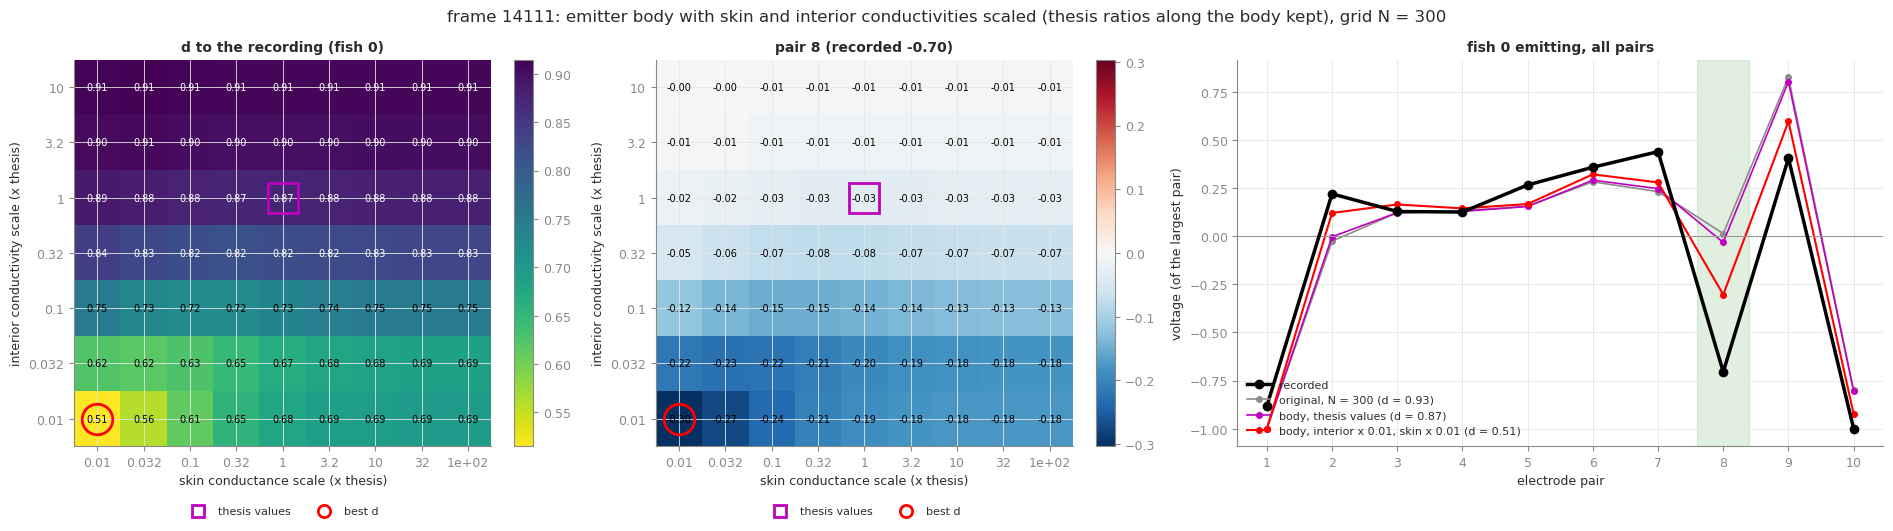

In [8]:
SKIN_SCALES = np.logspace(-2, 2, 9)                                 # x thesis skin (4e-4 / 5e-3 / 3e-3 S/cm^2)
INT_SCALES = np.logspace(-2, 1, 7)                                  # x thesis interior (0.004 - 0.015 S/cm, i.e. 40 - 150 x water)
NS = 300; spec = VARIANTS[-1][1]
D = np.zeros((len(INT_SCALES), len(SKIN_SCALES))); V8 = np.zeros_like(D); US = {}
for a_, si in enumerate(INT_SCALES):
    for b_, ss in enumerate(SKIN_SCALES):
        p, _, _ = solve_variant(em, spec, NS, ss, si); v = -pair_voltages(p, c['pairs'], NS); u = v / np.abs(v).max()
        US[a_, b_] = u; D[a_, b_] = np.linalg.norm(u - r); V8[a_, b_] = u[k8]
ab = np.unravel_index(D.argmin(), D.shape); a1 = (list(INT_SCALES).index(1.0), list(SKIN_SCALES).index(1.0))
print(f"frame {FRAME}, fish {em}, grid N = {NS}: d to the recording (rows: interior scale, columns: skin scale)")
print(f"{'int / skin':>10s} " + ' '.join(f'{x:>6.2g}' for x in SKIN_SCALES))
for a_, si in enumerate(INT_SCALES): print(f"{si:>10.2g} " + ' '.join(f'{x:6.3f}' for x in D[a_]))
print(f"\npair {PAIR} (recorded {r[k8]:+.2f}):")
for a_, si in enumerate(INT_SCALES): print(f"{si:>10.2g} " + ' '.join(f'{x:+6.3f}' for x in V8[a_]))

best = dict(int_scale=INT_SCALES[ab[0]], skin_scale=SKIN_SCALES[ab[1]])
print(f"\nbest: interior x {best['int_scale']:.2g} ({0.004 * best['int_scale']:.2g}-{0.015 * best['int_scale']:.2g} S/cm), skin x {best['skin_scale']:.2g} "
      f"(side skin {3e-3 * best['skin_scale']:.2g} S/cm^2): d = {D[ab]:.3f} (thesis values d = {D[a1]:.3f}; original model at N = {NS}: {np.linalg.norm(uo2 - r):.3f})")
print(f"{'':28s}" + ' '.join(f'{"p" + str(q):>6s}' for q in c['pair_ids']))
for lab, u in (('recorded', r), (f'original (N = {NS})', uo2), ('thesis values', US[a1]), ('best scales', US[ab])):
    print(f"{lab:28s}" + ' '.join(f'{x:+6.2f}' for x in u))
dd = {}
for lab, kw in (('thesis values', dict(skin_scale=1.0, int_scale=1.0)), ('best scales', best)):
    for f in c['fish']:
        if f == em: dd[lab, f] = D[a1] if lab == 'thesis values' else D[ab]; continue
        p, _, _ = solve_variant(f, spec, NS, **kw); v = -pair_voltages(p, c['pairs'], NS); dd[lab, f] = np.linalg.norm(v / np.abs(v).max() - r)
    print(f"{lab}: d for each candidate fish " + ', '.join(f'fish {f} {dd[lab, f]:.2f}' for f in c['fish']) + f" -> pick fish {min(c['fish'], key=lambda f: dd[lab, f])}")

fig, axs = plt.subplots(1, 3, figsize=(19, 5.4), gridspec_kw=dict(width_ratios=[1, 1, 1.4]))
for a, Z, lab, cmap in ((axs[0], D, f'd to the recording (fish {em})', 'viridis_r'), (axs[1], V8, f'pair {PAIR} (recorded {r[k8]:+.2f})', 'RdBu_r')):
    lim = dict(vmin=-np.abs(Z).max(), vmax=np.abs(Z).max()) if cmap == 'RdBu_r' else {}
    im = a.imshow(Z, origin='lower', cmap=cmap, aspect='auto', **lim); plt.colorbar(im, ax=a, fraction=0.046)
    for (i_, j_), z in np.ndenumerate(Z): a.text(j_, i_, f'{z:.2f}', ha='center', va='center', fontsize=7, color='w' if cmap == 'viridis_r' and z > Z.min() + 0.6 * np.ptp(Z) else 'k')
    a.plot(a1[1], a1[0], 's', mfc='none', mec='m', ms=22, mew=2, label='thesis values'); a.plot(ab[1], ab[0], 'o', mfc='none', mec='r', ms=22, mew=2, label='best d')
    a.set(xticks=range(len(SKIN_SCALES)), xticklabels=[f'{x:.2g}' for x in SKIN_SCALES], yticks=range(len(INT_SCALES)), yticklabels=[f'{x:.2g}' for x in INT_SCALES],
          xlabel='skin conductance scale (x thesis)', ylabel='interior conductivity scale (x thesis)', title=lab)
    a.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, markerscale=0.4, frameon=False)
a = axs[2]; x = np.arange(len(c['pair_ids']))
a.plot(x, r, 'k-o', lw=2.5, label='recorded', zorder=5)
a.plot(x, uo2, 'o-', color='0.55', lw=1.2, ms=4, label=f'original, N = {NS} (d = {np.linalg.norm(uo2 - r):.2f})')
a.plot(x, US[a1], 'o-', color='m', lw=1.2, ms=4, label=f'body, thesis values (d = {D[a1]:.2f})')
a.plot(x, US[ab], 'o-', color='r', lw=1.5, ms=4, label=f"body, interior x {best['int_scale']:.2g}, skin x {best['skin_scale']:.2g} (d = {D[ab]:.2f})")
a.axvspan(k8 - 0.4, k8 + 0.4, color='g', alpha=0.12); a.axhline(0, color='0.6', lw=0.8)
a.set(xticks=x, xticklabels=c['pair_ids'], xlabel='electrode pair', ylabel='voltage (of the largest pair)', title=f'fish {em} emitting, all pairs')
a.legend(fontsize=8, loc='lower left')
fig.suptitle(f'frame {FRAME}: emitter body with skin and interior conductivities scaled (thesis ratios along the body kept), grid N = {NS}', fontsize=12)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_conductivity_scan.png', dpi=100, bbox_inches='tight'); plt.show()

## Original midline model, other fish's conductivities scanned

Back to the original model: the emitter transparent, point currents along its mask midline (sink at the tail tip, `multipole_sources`,
sink_frac = 0). Only the **other two fish** change: their interior conductivity (× water) and their skin conductance (× the BEM
skin, which is as resistive as 0.1 cm of water, 1e-3 S/cm² with water at 1e-4 S/cm), both up and down. Interior < 1 = bodies more
resistive than water; skin × ≪ 1 = insulating skin; interior ≈ 1 with skin × ≫ 1 = transparent bodies. The same values are used
for every candidate emitter (each time for the two fish that do not emit), so the pick can be checked. Grid N = 150 as in the
pipeline (best values checked at N = 300). BEM values (interior 100, skin × 1) reproduce the cached model exactly.

frame 14111, fish 0 emitting (original midline sources), grid N = 150; rows: other fish interior (x water), columns: skin (x BEM)

d to the recording
int / skin  1e-03  1e-02  1e-01  1e+00  1e+01  1e+02  1e+03
      0.01  0.883  0.882  0.882  0.882  0.882  0.882  0.882
       0.1  0.883  0.880  0.879  0.879  0.880  0.880  0.880
       0.3  0.883  0.880  0.880  0.881  0.881  0.881  0.881
         1  0.883  0.881  0.881  0.883  0.884  0.884  0.884
         3  0.883  0.881  0.884  0.887  0.888  0.889  0.889
        10  0.883  0.883  0.890  0.897  0.898  0.899  0.899
        30  0.883  0.884  0.897  0.908  0.911  0.912  0.912
       100  0.883  0.884  0.902  0.918  0.922  0.923  0.923
       300  0.883  0.884  0.904  0.922  0.927  0.928  0.928
     1e+03  0.883  0.884  0.905  0.924  0.929  0.930  0.930
     1e+04  0.883  0.884  0.905  0.924  0.930  0.930  0.931

pair 8 (recorded -0.70)
int / skin  1e-03  1e-02  1e-01  1e+00  1e+01  1e+02  1e+03
      0.01 -0.077 -0.075 -0.075 -0.075 -0.075

N = 300 check: BEM d = 0.931, best d = 0.881


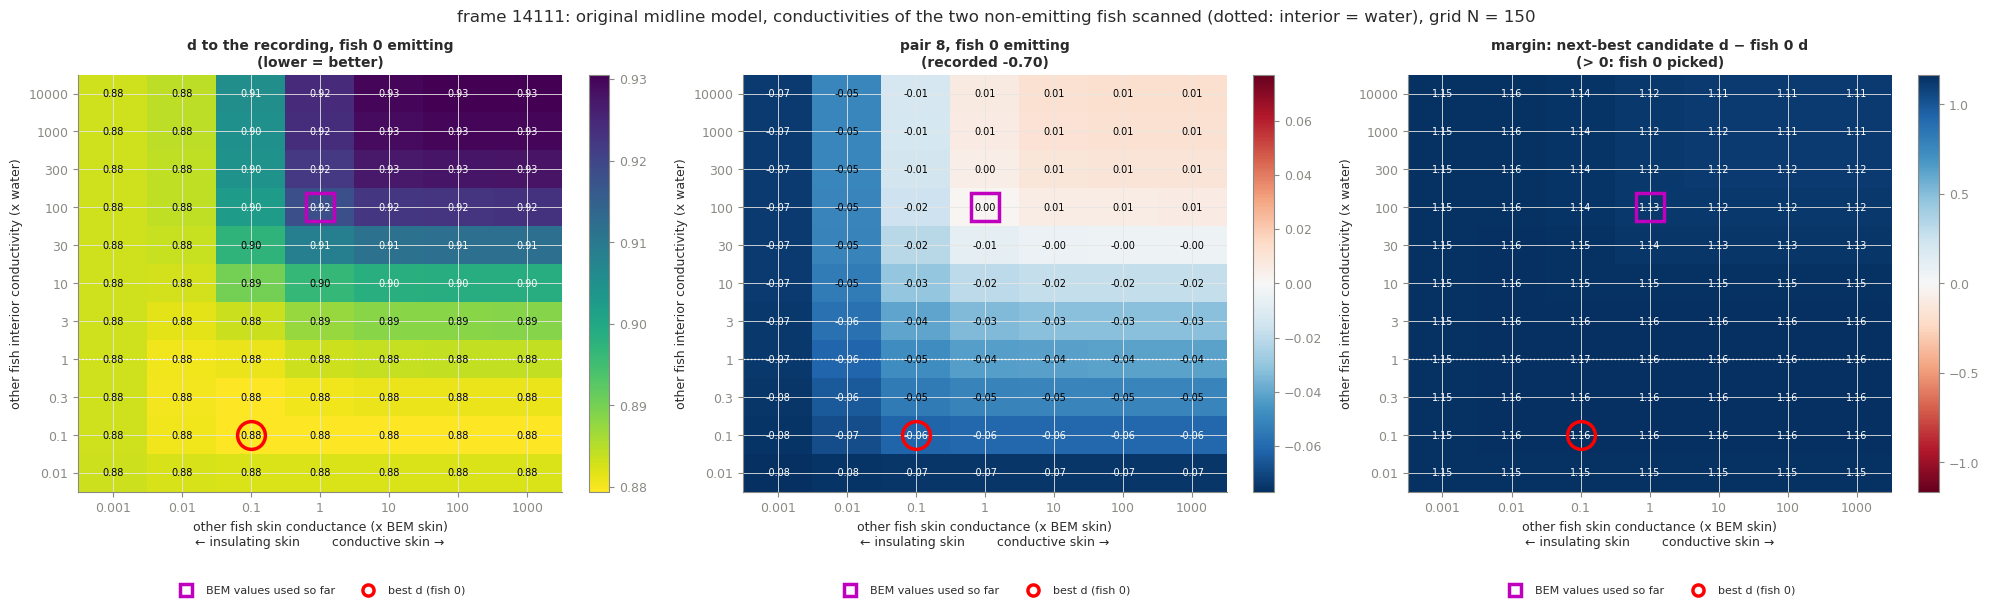

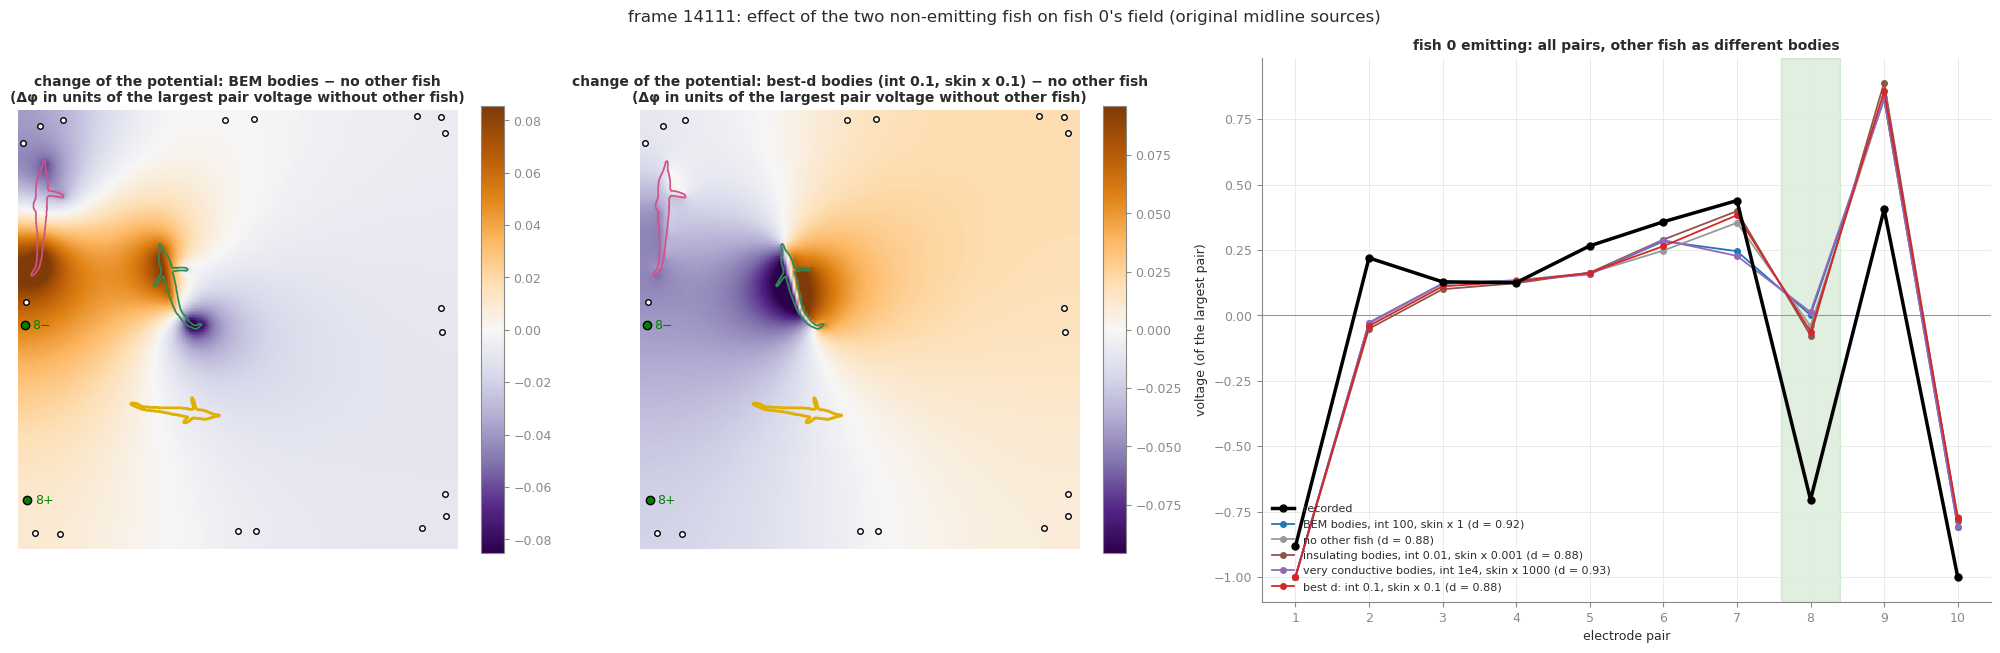

In [9]:
OF_INT = np.array([0.01, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000, 1e4])  # other fish interior, x water
OF_SKIN = np.array([1e-3, 1e-2, 1e-1, 1, 10, 100, 1e3])                   # other fish skin conductance, x BEM skin (0.1 cm of water)
def other_fish_u(f, g_int, skin_x, N_=N, bodies=True):
    '''Pattern (x -1, max |v| = 1) with fish f emitting (original midline sources), the other fish with interior g_int, skin skin_x.'''
    occ = occupancy_field(fm, N_, skip=f) if bodies else np.zeros((N_, N_)); ins = occ > 0.5
    gsk = 1 / (0.1 / skin_x / SKIN_T + 1 / g_int)                    # skin σ (x water) over SKIN_T
    A_ = build_A_var(occ, N_, SKIN_T / ((P - 1) / (N_ - 1) / ex.PX_PER_CM), np.where(ins, g_int, 1.0), np.where(ins, gsk, 1.0))
    b = build_multipole_b(*multipole_sources(mids[f], I0=1.0, sink_frac=0.0), 1 / (N_ - 1), N_)
    ph = unflatten_to_grid(solve_potential(A_, b), N_).real; v = -pair_voltages(ph, c['pairs'], N_)
    return v / np.abs(v).max(), ph
for f in c['fish']: assert np.allclose(other_fish_u(f, 100.0, 1.0)[0], U[f], atol=1e-6)   # BEM values = cached model

DO = np.zeros((len(c['fish']), len(OF_INT), len(OF_SKIN))); UO = {}
for fi, f in enumerate(c['fish']):
    for a_, gi_ in enumerate(OF_INT):
        for b_, sx in enumerate(OF_SKIN):
            u, _ = other_fish_u(f, gi_, sx); UO[f, a_, b_] = u; DO[fi, a_, b_] = np.linalg.norm(u - r)
e_ = c['fish'].index(em); D0 = DO[e_]; P8 = np.array([[UO[em, a_, b_][k8] for b_ in range(len(OF_SKIN))] for a_ in range(len(OF_INT))])
MARGIN = np.delete(DO, e_, axis=0).min(axis=0) - D0                 # > 0: the true emitter is picked
ib = (list(OF_INT).index(100), list(OF_SKIN).index(1)); bb = np.unravel_index(D0.argmin(), D0.shape); wb = np.unravel_index(D0.argmax(), D0.shape)
u_none = other_fish_u(em, 1.0, 1.0, bodies=False)[0]
print(f"frame {FRAME}, fish {em} emitting (original midline sources), grid N = {N}; rows: other fish interior (x water), columns: skin (x BEM)")
for lab, Z, fmt in (('d to the recording', D0, '6.3f'), (f'pair {PAIR} (recorded {r[k8]:+.2f})', P8, '+6.3f'), ('margin: next-best candidate d - true emitter d', MARGIN, '+6.2f')):
    print(f"\n{lab}\n{'int / skin':>10s} " + ' '.join(f'{x:>6.0e}' for x in OF_SKIN))
    for a_, gi_ in enumerate(OF_INT): print(f"{gi_:>10.3g} " + ' '.join(f'{x:{fmt}}' for x in Z[a_]))
print(f"\nBEM (int 100, skin x 1): d = {D0[ib]:.3f} | best: int {OF_INT[bb[0]]:g}, skin x {OF_SKIN[bb[1]]:g}: d = {D0[bb]:.3f} | "
      f"worst: int {OF_INT[wb[0]]:g}, skin x {OF_SKIN[wb[1]]:g}: d = {D0[wb]:.3f} | no other fish: d = {np.linalg.norm(u_none - r):.3f}")
print(f"range of d over the whole scan: {D0.min():.3f} - {D0.max():.3f}; true emitter picked in {np.mean(MARGIN > 0):.0%} of the settings")
cases = [('recorded', r, 'k'), (f'BEM bodies, int 100, skin x 1 (d = {D0[ib]:.2f})', UO[em, ib[0], ib[1]], 'tab:blue'),
         (f'no other fish (d = {np.linalg.norm(u_none - r):.2f})', u_none, '0.6'),
         (f'insulating bodies, int 0.01, skin x 0.001 (d = {D0[0, 0]:.2f})', UO[em, 0, 0], 'tab:brown'),
         (f'very conductive bodies, int 1e4, skin x 1000 (d = {D0[-1, -1]:.2f})', UO[em, len(OF_INT) - 1, len(OF_SKIN) - 1], 'tab:purple'),
         (f'best d: int {OF_INT[bb[0]]:g}, skin x {OF_SKIN[bb[1]]:g} (d = {D0[bb]:.2f})', UO[em, bb[0], bb[1]], 'tab:red')]
print(f"\n{'':62s}" + ' '.join(f'{"p" + str(q):>6s}' for q in c['pair_ids']))
for lab, u, _ in cases: print(f"{lab[:62]:62s}" + ' '.join(f'{x:+6.2f}' for x in u))
ub2 = other_fish_u(em, OF_INT[bb[0]], OF_SKIN[bb[1]], N_=300)[0]; ui2 = other_fish_u(em, 100.0, 1.0, N_=300)[0]
print(f"N = 300 check: BEM d = {np.linalg.norm(ui2 - r):.3f}, best d = {np.linalg.norm(ub2 - r):.3f}")

fig, axs = plt.subplots(1, 3, figsize=(20, 6.3))                    # figure 1: the scan
for a, Z, lab, cmap, sym in ((axs[0], D0, f'd to the recording, fish {em} emitting\n(lower = better)', 'viridis_r', False),
                             (axs[1], P8, f'pair {PAIR}, fish {em} emitting\n(recorded {r[k8]:+.2f})', 'RdBu_r', True),
                             (axs[2], MARGIN, f'margin: next-best candidate d − fish {em} d\n(> 0: fish {em} picked)', 'RdBu', True)):
    lim = dict(vmin=-np.abs(Z).max(), vmax=np.abs(Z).max()) if sym else {}
    im = a.imshow(Z, origin='lower', cmap=cmap, aspect='auto', **lim); plt.colorbar(im, ax=a, fraction=0.046)
    for (i_, j_), z in np.ndenumerate(Z): a.text(j_, i_, f'{z:.2f}', ha='center', va='center', fontsize=7,
                                                 color='w' if np.mean(im.cmap(im.norm(z))[:3]) < 0.45 else 'k')
    a.plot(ib[1], ib[0], 's', mfc='none', mec='m', ms=20, mew=2.5, label='BEM values used so far')
    a.plot(bb[1], bb[0], 'o', mfc='none', mec='r', ms=20, mew=2.5, label=f'best d (fish {em})')
    a.axhline(list(OF_INT).index(1), color='w', lw=1, ls=':')
    a.set(xticks=range(len(OF_SKIN)), xticklabels=[f'{x:g}' for x in OF_SKIN], yticks=range(len(OF_INT)), yticklabels=[f'{x:g}' for x in OF_INT],
          xlabel='other fish skin conductance (x BEM skin)\n← insulating skin        conductive skin →', ylabel='other fish interior conductivity (x water)', title=lab)
    a.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, markerscale=0.4, frameon=False)
fig.suptitle(f'frame {FRAME}: original midline model, conductivities of the two non-emitting fish scanned (dotted: interior = water), grid N = {N}', fontsize=12)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_other_fish_scan.png', dpi=100, bbox_inches='tight'); plt.show()

ph_bem = other_fish_u(em, 100.0, 1.0)[1]; ph_best = other_fish_u(em, OF_INT[bb[0]], OF_SKIN[bb[1]])[1]; ph_none = other_fish_u(em, 1.0, 1.0, bodies=False)[1]
fig, axs = plt.subplots(1, 3, figsize=(20, 6.6), gridspec_kw=dict(width_ratios=[1, 1, 1.5]))   # figure 2: what the bodies do to the field
scl = np.abs(-pair_voltages(ph_none, c['pairs'], N)).max()          # potentials in units of the largest pair voltage without other fish
for a, dph, lab in ((axs[0], (ph_bem - ph_none) / scl, 'BEM bodies − no other fish'),
                    (axs[1], (ph_best - ph_none) / scl, f'best-d bodies (int {OF_INT[bb[0]]:g}, skin x {OF_SKIN[bb[1]]:g}) − no other fish')):
    vv = max(np.percentile(np.abs(dph), 99.5), 1e-6)
    im = a.imshow(dph, extent=[0, P - 1, P - 1, 0], cmap='PuOr_r', vmin=-vv, vmax=vv); plt.colorbar(im, ax=a, fraction=0.046)
    for o in c['fish']:
        if fm[o].any(): a.contour(fm[o].astype(float), levels=[0.5], colors=[c['fish_color'][o]], linewidths=2 if o == em else 1.2)
    for pid, pp_, pm_ in c['pairs']:
        for pt, sg in ((pp_, '+'), (pm_, '−')):
            y, x = pt * (P - 1); a.plot(x, y, 'o', color='g' if pid == PAIR else 'w', mec='k', ms=6 if pid == PAIR else 4)
            if pid == PAIR: a.text(x + 15, y, f'{PAIR}{sg}', fontsize=9, color='g', va='center')
    a.set_axis_off(); a.set_title(f'change of the potential: {lab}\n(Δφ in units of the largest pair voltage without other fish)', fontsize=10)
a = axs[2]; x = np.arange(len(c['pair_ids']))
for lab, u, col in cases: a.plot(x, u, 'o-', color=col, lw=2.5 if col == 'k' else 1.3, ms=5 if col == 'k' else 4, label=lab, zorder=5 if col == 'k' else 3)
a.axvspan(k8 - 0.4, k8 + 0.4, color='g', alpha=0.12); a.axhline(0, color='0.6', lw=0.8)
a.set(xticks=x, xticklabels=c['pair_ids'], xlabel='electrode pair', ylabel='voltage (of the largest pair)', title=f'fish {em} emitting: all pairs, other fish as different bodies')
a.legend(fontsize=8, loc='lower left')
fig.suptitle(f'frame {FRAME}: effect of the two non-emitting fish on fish {em}\'s field (original midline sources)', fontsize=12)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_other_fish_effect.png', dpi=100, bbox_inches='tight'); plt.show()

## Notes

**Frame 14111** (EOD row 9410; both right; fish 0 9.5 cm from the nearest fish, mask 12.2 cm, head–tail as SLEAP):
- fish 0's field is a dipole along its body (sink at the tail, positive towards the head), with the zero-potential line crossing it
  near mid-body; my model fits the recording best for fish 0 (d = 0.92 vs 2.04 and 2.75); Denis agrees (similarity 0.81).
- the largest misfit is **pair 8**: recorded −0.70, model ≈ 0. Both of its electrodes (8+ and 8−, on the left wall) sit in fish 0's
  negative lobe at the same potential (−0.07), so the model gives no voltage; Denis' model also gives ≈ 0 there.
- smaller misfits: pair 2 (recorded −0.1 then +0.2; model ≈ 0) and pair 5 (recorded +0.25, model +0.1).

- **tests on pair 8** (all in `EOD_debug_frames_3fish_frame14111.ipynb`, figures `debug_frames/frame14111_*.png`):
  - orientation: body 8° off perpendicular to the 8−→8+ axis, tail (last 10–30 %) 13–20° off.
  - rotating the whole midline clockwise: pair 8 +0.00 → −0.42 at 20° (d 0.92 → 0.41), −0.56 at 30° (d rises again to 0.51).
  - 1–15 sink points at the tail (currents summing to 0): no change (pair 8 ≤ +0.05).
  - emitter as a body (thesis: skin by zone, interior profile, electric organ in the tail): pair 8 −0.03 at N = 300 (d 0.93 → 0.87).
    Scaling its skin/interior: best only at unphysical values (interior ≈ water): pair 8 −0.30, d 0.51.
  - other fish's interior 0.01–10⁴ × water, skin × 0.001–1000: d 0.88–0.93, pair 8 −0.08 to +0.01; only pair 7 moves (fish 1 sits
    between 7− and 7+; it shorts them when conductive).
  - not explained: only turning the current axis moves pair 8 much, and nothing reaches −0.70. Next suspect: pair 8's electrode
    positions / wiring (check across all good-frame EODs).
